# Parte Comum — Padronização, K-Means e Métricas (Wine Quality)
Projeto Final AVD 2026.2 — Grupo 6.

Fonte: Cortez et al. (2009), Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 47(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016

Responsável original: **Sacramento**. Colaboração na complementação: **Arthur Borges**.

## Configuração

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
candidates = [Path.cwd(), *Path.cwd().parents]
DATA = next((r / 'data/parte_comum/wine_quality/winequality-combined.csv' for r in candidates if (r / 'data/parte_comum/wine_quality/winequality-combined.csv').is_file()), None)
if DATA is None:
    DATA = next((r / 'winequality-combined.csv' for r in candidates if (r / 'winequality-combined.csv').is_file()), None)
if DATA is None:
    raise FileNotFoundError('Coloque winequality-combined.csv em data/parte_comum/wine_quality/')
ROOT = DATA.parents[3] if DATA.parent.name == 'wine_quality' else DATA.parent
OUT = ROOT / 'out/parte_comum/wine_quality'
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA, sep=';')
coluna_classe = 'quality'
num = df.select_dtypes(include='number').columns.drop(coluna_classe).tolist()
sns.set_theme(style='whitegrid')
def salvar(nome):
    plt.tight_layout()
    plt.savefig(OUT / nome, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
print(DATA, df.shape)

c:\Users\gusta\OneDrive\Documentos\AVD\projeto-avd-2026-2-pump-it-up-classificatorio\data\parte_comum\wine_quality\winequality-combined.csv (6497, 13)


## 1. Preparação e padronização

In [2]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, silhouette_score, davies_bouldin_score
# Configuração inicial: manter registros e incluir tipo como indicador binário.
REMOVER_DUPLICATAS = False
INCLUIR_TIPO = True
if REMOVER_DUPLICATAS: df=df.drop_duplicates().reset_index(drop=True)
X=df[num].copy()
if INCLUIR_TIPO: X['wine_type_red'] = df.wine_type.eq('red').astype(int)
y=df.quality.reset_index(drop=True)
Z=StandardScaler().fit_transform(X)
classes=sorted(y.unique())
pca=PCA(n_components=2,random_state=42)
coords=pca.fit_transform(Z)
print('Classes:',classes,'Variância PCA:',pca.explained_variance_ratio_)

Classes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] Variância PCA: [0.3174498  0.21072897]


A nota quality foi excluída das entradas para evitar que os rótulos orientem o agrupamento. A padronização coloca atributos com unidades distintas em escalas comparáveis. O tipo de vinho foi incluído como indicador binário padronizado, podendo influenciar a separação dos grupos. Foram mantidos os registros duplicados e valores atípicos, em conformidade com a EDA.

## 2. Passada 1 — k livre (Método do Cotovelo)

,k,inercia,silhouette,davies_bouldin,reducao_percentual
0,2,56403.476541,0.335444,1.335601,NaN
1,3,45875.739036,0.252266,1.419573,18.665051
2,4,41190.132497,0.251817,1.481230,10.213692
3,5,38471.552554,0.182685,1.799612,6.600076
4,6,36356.034008,0.186258,1.662378,5.498916
5,7,34418.178959,0.182218,1.597726,5.330216
6,8,33092.248132,0.162486,1.687326,3.852414
7,9,31945.039268,0.143029,1.766083,3.466700
8,10,30958.047193,0.141592,1.759622,3.089657


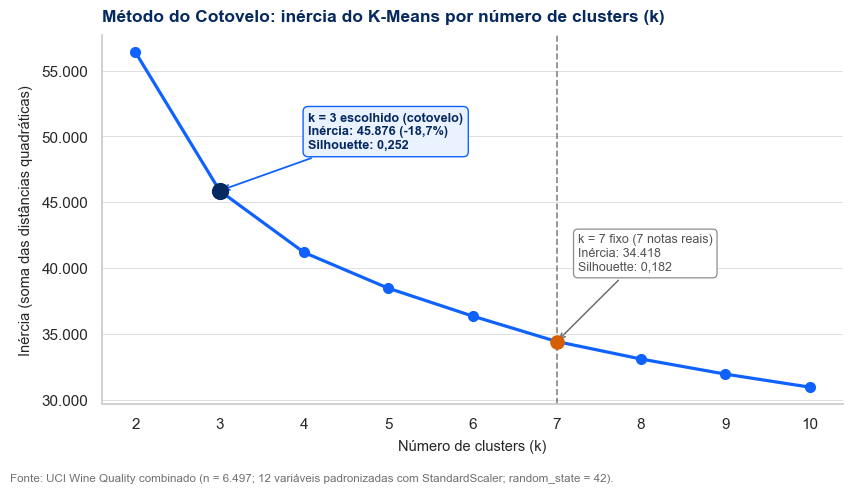

In [3]:
# [IA] ChatGPT / Gemini – Método do Cotovelo e métricas internas com padronização visual (Seção 2.1)
from matplotlib.ticker import FuncFormatter
modelos={}; linhas=[]
for k in range(2,11):
    m=KMeans(n_clusters=k,random_state=42,n_init=10).fit(Z)
    modelos[k]=m
    linhas.append({'k':k,'inercia':m.inertia_,'silhouette':silhouette_score(Z,m.labels_,sample_size=min(2000,len(Z)),random_state=42),'davies_bouldin':davies_bouldin_score(Z,m.labels_)})
avaliacao=pd.DataFrame(linhas)
avaliacao['reducao_percentual']= -avaliacao.inercia.pct_change()*100
display(avaliacao); avaliacao.to_csv(OUT/'avaliacao_clusters.csv',index=False)

fmt_milhar = FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", "."))
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.plot(avaliacao.k, avaliacao.inercia, marker='o', markersize=7, linewidth=2.3, color='#0F62FE', label='Inércia (soma de distâncias quadráticas)')

# Destaque do cotovelo escolhido (k = 3) e referencia da Passada 2 (k = 7)
row3 = avaliacao.loc[avaliacao['k'] == 3].iloc[0]
row7 = avaliacao.loc[avaliacao['k'] == 7].iloc[0]
ax.scatter([3], [row3['inercia']], s=130, color='#062A5F', zorder=5)
ax.annotate(
    f"k = 3 escolhido (cotovelo)\nInércia: {row3['inercia']:,.0f} (-{row3['reducao_percentual']:.1f}%)\nSilhouette: {row3['silhouette']:.3f}".replace(",", "X").replace(".", ",").replace("X", "."),
    xy=(3, row3['inercia']), xytext=(4.05, row3['inercia'] + 3200),
    fontsize=9.2, fontweight='bold', color='#062A5F',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#EAF2FF', edgecolor='#0F62FE', linewidth=1.0),
    arrowprops=dict(arrowstyle='->', color='#0F62FE', lw=1.3),
)
ax.axvline(7, color='#6F6F6F', linestyle='--', linewidth=1.2, alpha=0.85)
ax.scatter([7], [row7['inercia']], s=90, color='#D55E00', zorder=5)
ax.annotate(
    f"k = 7 fixo (7 notas reais)\nInércia: {row7['inercia']:,.0f}\nSilhouette: {row7['silhouette']:.3f}".replace(",", "X").replace(".", ",").replace("X", "."),
    xy=(7, row7['inercia']), xytext=(7.25, row7['inercia'] + 5400),
    fontsize=9.0, color='#525252',
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#FFFFFF', edgecolor='#8D8D8D', linewidth=0.9),
    arrowprops=dict(arrowstyle='->', color='#6F6F6F', lw=1.1),
)

ax.set_xticks(avaliacao.k)
ax.yaxis.set_major_formatter(fmt_milhar)
ax.set_title('Método do Cotovelo: inércia do K-Means por número de clusters (k)', fontsize=12.5, fontweight='bold', color='#062A5F', pad=10, loc='left')
ax.set_xlabel('Número de clusters (k)', fontsize=10.5, labelpad=6)
ax.set_ylabel('Inércia (soma das distâncias quadráticas)', fontsize=10.5, labelpad=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', visible=False)
ax.grid(axis='y', color='#E0E0E0', linewidth=0.7)
ax.set_axisbelow(True)
fig.text(0.01, -0.02, 'Fonte: UCI Wine Quality combinado (n = 6.497; 12 variáveis padronizadas com StandardScaler; random_state = 42).', fontsize=8.4, color='#6F6F6F')
salvar('metodo_cotovelo.png')


Após k = 3 a diferença gradual vai diminuindo significativamente, portanto foi escolhido k = 3.

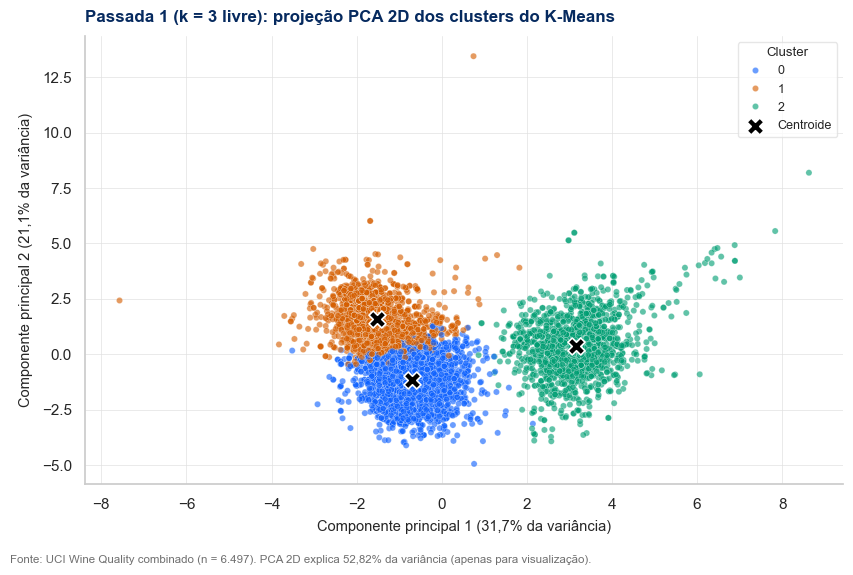

In [4]:
# [IA] ChatGPT / Gemini – visualização PCA 2D dos clusters com variância explicada e centroides
K_LIVRE = 3
if K_LIVRE not in modelos: raise ValueError('Escolha K_LIVRE entre 2 e 10 após analisar o cotovelo.')
K_FIXO = len(classes)
livre = modelos[K_LIVRE]

PALETA_CLUSTERS = ['#0F62FE', '#D55E00', '#009E73', '#E69F00', '#6929C4', '#062A5F', '#8D8D8D', '#CC79A7', '#56B4E9', '#198038']

def visualizar(modelo, nome, titulo=None):
    k_atual = modelo.n_clusters
    ordem = [str(i) for i in range(k_atual)]
    pal = {str(i): PALETA_CLUSTERS[i % len(PALETA_CLUSTERS)] for i in range(k_atual)}
    pc1_pct = pca.explained_variance_ratio_[0] * 100
    pc2_pct = pca.explained_variance_ratio_[1] * 100
    tot_pct = pc1_pct + pc2_pct

    fig, ax = plt.subplots(figsize=(8.6, 5.6))
    sns.scatterplot(
        x=coords[:, 0], y=coords[:, 1],
        hue=modelo.labels_.astype(str), hue_order=ordem, palette=pal,
        s=20, alpha=0.62, edgecolor='white', linewidth=0.25, ax=ax
    )
    centros_2d = pca.transform(modelo.cluster_centers_)
    ax.scatter(
        centros_2d[:, 0], centros_2d[:, 1],
        marker='X', s=150, color='#000000', edgecolor='#FFFFFF', linewidth=1.2,
        zorder=6, label='Centroide'
    )
    tit = titulo or f"Projeção PCA 2D dos clusters (k = {k_atual})"
    ax.set_title(tit, fontsize=12.2, fontweight='bold', color='#062A5F', pad=10, loc='left')
    ax.set_xlabel(f"Componente principal 1 ({pc1_pct:.1f}% da variância)".replace(".", ","), fontsize=10.5, labelpad=6)
    ax.set_ylabel(f"Componente principal 2 ({pc2_pct:.1f}% da variância)".replace(".", ","), fontsize=10.5, labelpad=6)
    ax.legend(title='Cluster', frameon=True, facecolor='white', edgecolor='#E0E0E0', fontsize=9, title_fontsize=9.5, ncol=2 if k_atual > 4 else 1, loc='upper right')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(color='#E0E0E0', linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)
    fig.text(0.01, -0.02, f"Fonte: UCI Wine Quality combinado (n = 6.497). PCA 2D explica {tot_pct:.2f}% da variância (apenas para visualização).".replace(f"{tot_pct:.2f}", f"{tot_pct:.2f}".replace(".", ",")), fontsize=8.3, color='#6F6F6F')
    salvar(nome + '.png')

visualizar(livre, 'clusters_livre', f'Passada 1 (k = {K_LIVRE} livre): projeção PCA 2D dos clusters do K-Means')


## 3. Passada 2 — k fixo

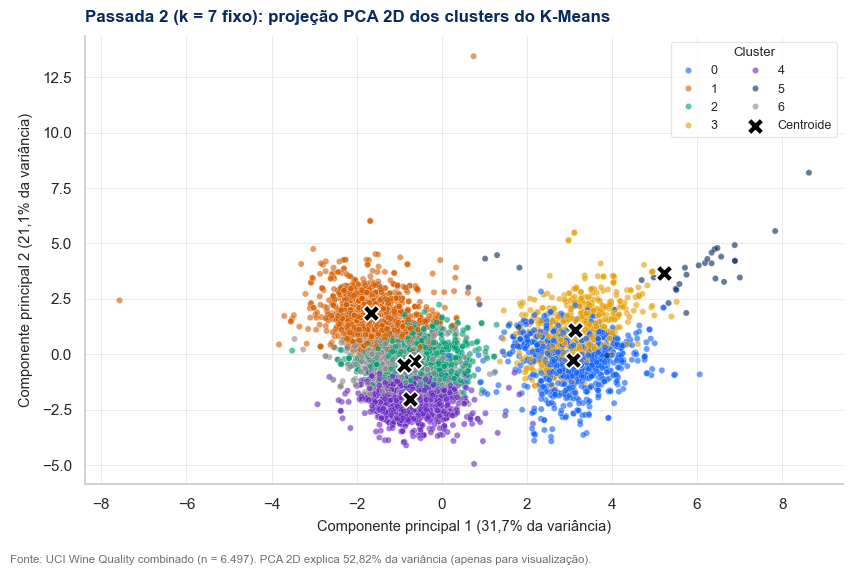

In [5]:
# [IA] ChatGPT / Gemini – execução e visualização da Passada 2 (k fixo = 7 notas)
fixo=modelos[K_FIXO] if K_FIXO in modelos else KMeans(n_clusters=K_FIXO,random_state=42,n_init=10).fit(Z)
visualizar(fixo, 'clusters_fixo', f'Passada 2 (k = {K_FIXO} fixo): projeção PCA 2D dos clusters do K-Means')


O k fixo é 7, correspondente às notas de 3 a 9. A inércia cai para 34.418,18, mas a Silhouette diminui para 0,1822 e Davies-Bouldin aumenta para 1,5977 em relação à Passada 1 (k = 3, com Silhouette 0,2523 e Davies-Bouldin 1,4196). A redução da inércia é esperada com mais centros e não demonstra, isoladamente, melhor agrupamento. O PCA é apenas uma projeção 2D (52,82% da variância) para visualização.

## 4. Mapeamento cluster → classe majoritária

In [6]:
# [IA] ChatGPT – apoio com pandas/scikit-learn e implementação
def mapear(modelo,nome):
    tabela=pd.crosstab(pd.Series(modelo.labels_,name='cluster'),y.rename('quality')).reindex(columns=classes,fill_value=0)
    display(tabela); tabela.to_csv(OUT/f'matriz_cluster_classe_{nome}.csv')
    mapa=tabela.idxmax(axis=1)
    print(mapa)
    return pd.Series(modelo.labels_).map(mapa)
pred_livre=mapear(livre,'livre'); pred_fixo=mapear(fixo,'fixo')

quality,3,4,5,6,7,8,9
cluster,,,,,,,
0,8,109,652,1368,728,145,4
1,12,50,804,839,156,30,1
2,10,57,682,629,195,18,0


cluster
0    6
1    6
2    5
dtype: int64


quality,3,4,5,6,7,8,9
cluster,,,,,,,
0,7,46,470,356,50,5,0
1,8,26,650,644,122,21,1
2,5,77,416,513,130,27,0
3,3,10,199,265,144,13,0
4,4,21,82,541,454,97,4
5,1,2,20,9,1,0,0
6,2,34,301,508,178,30,0


cluster
0    5
1    5
2    6
3    6
4    6
5    5
6    6
dtype: int64


## 5. Matriz de confusão e métricas

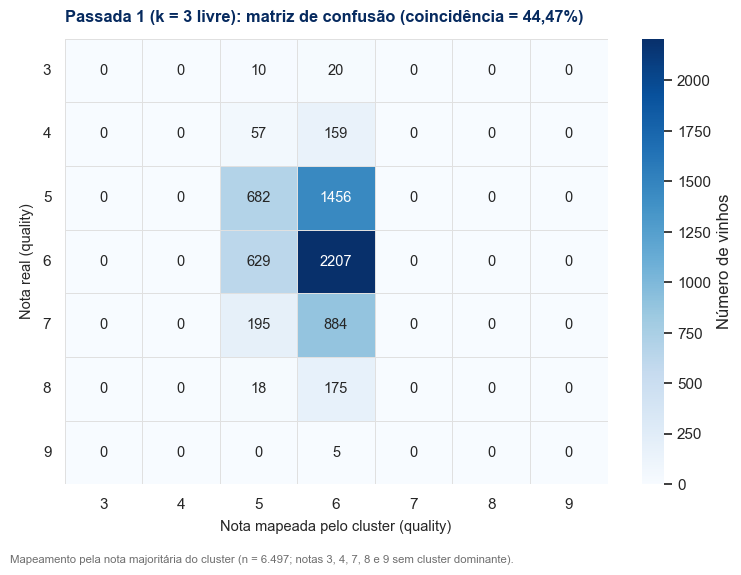

,precision,recall,f1-score,support
3,0.000000,0.000000,0.000000,30.000000
4,0.000000,0.000000,0.000000,216.000000
5,0.428661,0.318990,0.365782,2138.000000
6,0.449857,0.778209,0.570137,2836.000000
7,0.000000,0.000000,0.000000,1079.000000
8,0.000000,0.000000,0.000000,193.000000
9,0.000000,0.000000,0.000000,5.000000
accuracy,0.444667,0.444667,0.444667,0.444667
macro avg,0.125503,0.156743,0.133703,6497.000000
weighted avg,0.337429,0.444667,0.369240,6497.000000


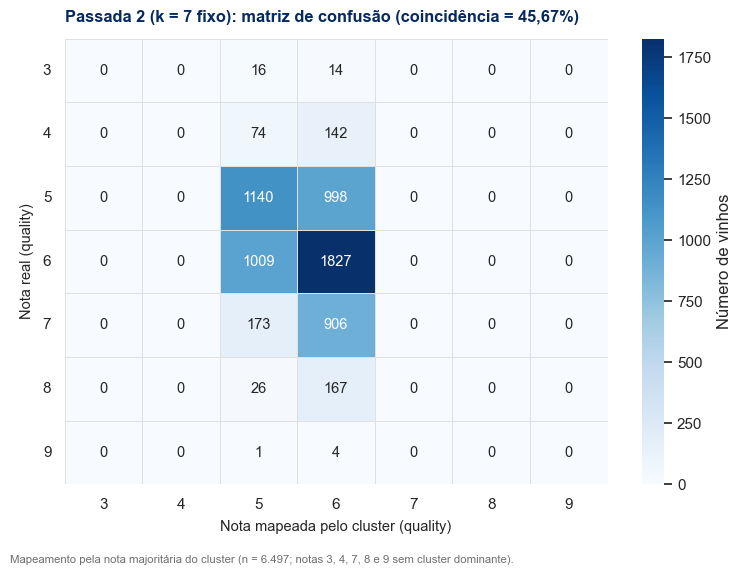

,precision,recall,f1-score,support
3,0.000000,0.000000,0.000000,30.000000
4,0.000000,0.000000,0.000000,216.000000
5,0.467405,0.533209,0.498143,2138.000000
6,0.450222,0.644217,0.530026,2836.000000
7,0.000000,0.000000,0.000000,1079.000000
8,0.000000,0.000000,0.000000,193.000000
9,0.000000,0.000000,0.000000,5.000000
accuracy,0.456672,0.456672,0.456672,0.456672
macro avg,0.131089,0.168204,0.146881,6497.000000
weighted avg,0.350337,0.456672,0.395288,6497.000000


,passada,k,inercia,acuracia,precision_macro,recall_macro,f1-score_macro
0,livre,3,45875.739036,0.444667,0.125503,0.156743,0.133703
1,fixo,7,34418.178959,0.456672,0.131089,0.168204,0.146881


In [7]:
# [IA] ChatGPT / Gemini – matrizes de confusão e métricas comparativas com títulos e eixos em pt-BR
def avaliar(modelo, pred, nome):
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=classes), index=classes, columns=classes)
    cm.to_csv(OUT / f'matriz_confusao_classes_{nome}.csv')
    acc = accuracy_score(y, pred)
    rotulo_passada = f"Passada 1 (k = {modelo.n_clusters} livre)" if nome == "livre" else f"Passada 2 (k = {modelo.n_clusters} fixo)"
    acc_txt = f"{acc * 100:.2f}%".replace(".", ",")

    fig, ax = plt.subplots(figsize=(7.6, 5.6))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', linewidths=0.5, linecolor='#E0E0E0',
        cbar_kws={'label': 'Número de vinhos'}, annot_kws={'size': 10.5}, ax=ax
    )
    ax.set_title(f"{rotulo_passada}: matriz de confusão (coincidência = {acc_txt})",
                 fontsize=11.8, fontweight='bold', color='#062A5F', pad=12, loc='left')
    ax.set_xlabel('Nota mapeada pelo cluster (quality)', fontsize=10.5, labelpad=6)
    ax.set_ylabel('Nota real (quality)', fontsize=10.5, labelpad=6)
    plt.yticks(rotation=0)
    fig.text(0.01, -0.02, 'Mapeamento pela nota majoritária do cluster (n = 6.497; notas 3, 4, 7, 8 e 9 sem cluster dominante).', fontsize=8.2, color='#6F6F6F')
    salvar(f'matriz_confusao_{nome}.png')

    rel = classification_report(y, pred, labels=classes, output_dict=True, zero_division=0)
    tabela = pd.DataFrame(rel).T; display(tabela); tabela.to_csv(OUT / f'metricas_{nome}.csv')
    return {'passada': nome, 'k': modelo.n_clusters, 'inercia': modelo.inertia_, 'acuracia': acc, **{f'{m}_macro': rel['macro avg'][m] for m in ['precision', 'recall', 'f1-score']}}

comparacao = pd.DataFrame([avaliar(livre, pred_livre, 'livre'), avaliar(fixo, pred_fixo, 'fixo')])
display(comparacao); comparacao.to_csv(OUT / 'comparacao_passadas.csv', index=False)


Após o mapeamento por maioria, a coincidência global passa de 44,47% (k = 3) para 45,67% (k = 7), ganho de 1,20 ponto percentual. O F1 macro passa de 0,1337 para 0,1469. Em ambas as passadas, apenas as notas 5 e 6 são atribuídas aos clusters; as demais (3, 4, 7, 8 e 9) têm precisão e recall iguais a zero (zero_division=0). A classe 6 sozinha representa 43,65% da base, o que contextualiza o pequeno ganho da acurácia obtida. As métricas são calculadas na própria base agrupada, não em teste independente.

## 6. Discussão crítica

A Passada 1 (k = 3) apresenta melhores indicadores internos de separação (Silhouette 0,2523 vs. 0,1822), enquanto a Passada 2 (k = 7) tem uma concordância apenas ligeiramente maior com as notas originais (45,67% vs. 44,47%). As sete notas não correspondem a sete grupos naturais isolados: a qualidade é ordinal, as classes são fortemente desbalanceadas (notas 5 e 6 somam 76,56%) e atributos físico-químicos são muito semelhantes entre notas vizinhas. A inclusão do tipo de vinho (`wine_type_red`) também favorece agrupamentos por composição (tinto vs. branco) em vez de qualidade. Uma análise adicional sem esse indicador permitiria avaliar sua influência. Os resultados confirmam que o K-Means revela perfis físico-químicos, mas não substitui um classificador supervisionado.